# PIPELINE THỰC NGHIỆM TÌM KIẾM ĐA PHƯƠNG THỨC
**Đề tài:** Tìm kiếm đa phương thức các địa điểm du lịch ở miền Tây Nam Bộ Việt Nam trên bản đồ

## 1. Thiết lập môi trường Colab, Làm phẳng dữ liệu & Kiểm tra 866 đường dẫn ảnh
### Bước 1.1: Mount Google Drive, định nghĩa đường dẫn & cài đặt thư viện

In [2]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Định nghĩa các đường dẫn thư mục
PROJECT_DIR = "/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN"
BASE_DIR = os.path.join(PROJECT_DIR, "notebooks")

RAW_DATA_DIR = os.path.join(PROJECT_DIR, "DATASET", "raw")
if not os.path.exists(RAW_DATA_DIR) and os.path.exists(os.path.join(PROJECT_DIR, "dataset", "raw")):
    RAW_DATA_DIR = os.path.join(PROJECT_DIR, "dataset", "raw")

RAW_JSON_PATH = os.path.join(RAW_DATA_DIR, "raw_dataset.json")
VNCORENLP_DIR = os.path.join(BASE_DIR, "vncorenlp_model")
FAISS_STORE_DIR = os.path.join(BASE_DIR, "outputs", "faiss_store")
EXPERIMENTS_DIR = os.path.join(BASE_DIR, "outputs", "experiments")

for folder in [BASE_DIR, VNCORENLP_DIR, FAISS_STORE_DIR, EXPERIMENTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print(f"BASE_DIR        : {BASE_DIR}")
print(f"RAW_DATA_DIR    : {RAW_DATA_DIR}")
print(f"RAW_JSON_PATH   : {RAW_JSON_PATH} (Tồn tại: {os.path.exists(RAW_JSON_PATH)})")
print(f"VNCORENLP_DIR   : {VNCORENLP_DIR}")
print(f"FAISS_STORE_DIR : {FAISS_STORE_DIR}")
print(f"EXPERIMENTS_DIR : {EXPERIMENTS_DIR}")
assert os.path.exists(RAW_JSON_PATH), f"Không tìm thấy file {RAW_JSON_PATH}. Hãy kiểm tra lại đường dẫn trên Google Drive!"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_DIR        : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks
RAW_DATA_DIR    : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/DATASET/raw
RAW_JSON_PATH   : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/DATASET/raw/raw_dataset.json (Tồn tại: True)
VNCORENLP_DIR   : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/vncorenlp_model
FAISS_STORE_DIR : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store
EXPERIMENTS_DIR : /content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/experiments


In [3]:
# Cài đặt môi trường Java 11 cho VnCoreNLP và các thư viện Python cần thiết
!apt-get update -qq && apt-get install -y -qq openjdk-11-jdk-headless
!pip install -q transformers torch faiss-cpu py_vncorenlp scikit-learn pillow pandas tqdm joblib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-11-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-11-jre-headless_11.0.33+9-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jre-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
Selecting previously unselected package openjdk-11-jdk-headless:amd64.
Preparing to unpack .../openjdk-11-jdk-headless_11.0.33+9-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jdk-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
Setting up openjdk-11-jre-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/jjs to provide /usr/bin/jjs (jjs) in auto mode
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/rmid to provide /us

### Bước 1.2: Làm phẳng dữ liệu (`raw_dataset.json`) & Kiểm tra toàn bộ 866 file ảnh, chuyển kênh màu `.convert("RGB")`

In [4]:
import json
from collections import Counter
from PIL import Image
from tqdm.auto import tqdm

with open(RAW_JSON_PATH, "r", encoding="utf-8-sig") as f:
    raw_dataset = json.load(f)

kho1_records = []  # 268 đoạn mô tả địa điểm (description_parts)
kho2_records = []  # 866 cặp ảnh - chú thích (image_texts)
place_ids = []

for group_name, places in raw_dataset.items():
    for place in places:
        place_id = place["id"]
        place_name = place["name"]
        place_ids.append(place_id)

        # Danh sách Kho 1 (description_parts)
        for part in place["description_parts"]:
            kho1_records.append({
                "faiss_id": len(kho1_records),
                "desc_id": part["id"],
                "place_id": place_id,
                "place_name": place_name,
                "order": part["order"],
                "raw_text": part["text"],
                "segmented_text": "",
            })

        # Danh sách Kho 2 (image_texts)
        for img_item in place["image_texts"]:
            image_path = img_item["image"]
            real_path = os.path.join(RAW_DATA_DIR, image_path)
            kho2_records.append({
                "faiss_id": len(kho2_records),
                "image_id": img_item["id"],
                "place_id": place_id,
                "place_name": place_name,
                "image_path": image_path,
                "real_path": real_path,
                "raw_caption": img_item["text"],
                "segmented_caption": "",
            })

print(f"Số cụm vùng hành chính (current) : {len(raw_dataset)}")
print(f"Tổng số địa điểm (place_id)      : {len(place_ids)}")
print(f"Tổng số đoạn mô tả (Kho 1)       : {len(kho1_records)}")
print(f"Tổng số cặp Ảnh - Caption (Kho 2): {len(kho2_records)}")

assert len(place_ids) == 32, f"Kỳ vọng 32 địa điểm, thực tế: {len(place_ids)}"
assert len(kho1_records) == 268, f"Kỳ vọng 268 đoạn mô tả, thực tế: {len(kho1_records)}"
assert len(kho2_records) == 866, f"Kỳ vọng 866 cặp ảnh-caption, thực tế: {len(kho2_records)}"
assert len(set(place_ids)) == 32, "place_id bị trùng"
assert len({r["desc_id"] for r in kho1_records}) == 268, "desc_id bị trùng"
assert len({r["image_id"] for r in kho2_records}) == 866, "image_id bị trùng"

# Kiểm tra toàn bộ 866 đường dẫn ảnh thực tế và chuyển kênh màu .convert('RGB')
missing_files = []
corrupted_files = []
format_counter = Counter()
mode_counter = Counter()

for r in tqdm(kho2_records, desc="Kiểm tra 866 ảnh & chuyển .convert('RGB')"):
    if not os.path.exists(r["real_path"]):
        missing_files.append((r["image_id"], r["image_path"]))
        continue
    try:
        with Image.open(r["real_path"]) as img:
            format_counter[img.format] += 1
            mode_counter[img.mode] += 1
            rgb_img = img.convert("RGB")
            assert rgb_img.mode == "RGB" and len(rgb_img.getbands()) == 3
    except Exception as err:
        corrupted_files.append((r["image_id"], r["image_path"], str(err)))

print("-" * 65)
print(f"Số file ảnh thiếu trên Drive : {len(missing_files)}")
print(f"Số file ảnh hỏng/lỗi đọc     : {len(corrupted_files)}")
print(f"Định dạng nhị phân gốc       : {dict(format_counter)}")
print(f"Hệ màu gốc trước khi chuyển  : {dict(mode_counter)} -> 100% đã chuyển sang RGB (3 kênh)")

assert len(missing_files) == 0, f"Phát hiện ảnh thiếu: {missing_files[:5]}"
assert len(corrupted_files) == 0, f"Phát hiện ảnh lỗi: {corrupted_files[:5]}"
print("[HOÀN TẤT MỐC 1] Đã kiểm tra thành công toàn bộ 866 đường dẫn ảnh và chuẩn hóa kênh màu RGB.")

Số cụm vùng hành chính (current) : 5
Tổng số địa điểm (place_id)      : 32
Tổng số đoạn mô tả (Kho 1)       : 268
Tổng số cặp Ảnh - Caption (Kho 2): 866


Kiểm tra 866 ảnh & chuyển .convert('RGB'):   0%|          | 0/866 [00:00<?, ?it/s]

-----------------------------------------------------------------
Số file ảnh thiếu trên Drive : 0
Số file ảnh hỏng/lỗi đọc     : 0
Định dạng nhị phân gốc       : {'JPEG': 576, 'WEBP': 254, 'PNG': 34, 'MPO': 2}
Hệ màu gốc trước khi chuyển  : {'RGB': 845, 'P': 8, 'RGBA': 13} -> 100% đã chuyển sang RGB (3 kênh)
[HOÀN TẤT MỐC 1] Đã kiểm tra thành công toàn bộ 866 đường dẫn ảnh và chuẩn hóa kênh màu RGB.


## 2: Khởi tạo `py_vncorenlp` & Tách từ tiếng Việt cho 268 đoạn mô tả (Kho 1) và 866 câu chú thích (Kho 2)

In [5]:
import unicodedata
import py_vncorenlp

# 1. Tải model VnCoreNLP vào VNCORENLP_DIR trên Google Drive nếu chưa có
jar_file = os.path.join(VNCORENLP_DIR, "VnCoreNLP-1.2.jar")
if not os.path.exists(jar_file):
    print("Đang tải model VnCoreNLP về Google Drive...")
    py_vncorenlp.download_model(save_dir=VNCORENLP_DIR)
else:
    print("Đã có sẵn model VnCoreNLP trên Google Drive.")

# 2. Khởi tạo VnCoreNLP an toàn
if "rdrsegmenter" not in globals() or rdrsegmenter is None:
    cwd = os.getcwd()
    try:
        rdrsegmenter = py_vncorenlp.VnCoreNLP(save_dir=VNCORENLP_DIR, annotators=["wseg"])
    finally:
        os.chdir(cwd)
    print(f"Đã khởi tạo VnCoreNLP thành công (cwd được giữ nguyên: {os.getcwd()}).")
else:
    print(f"Tái sử dụng rdrsegmenter đang chạy trong bộ nhớ (cwd: {os.getcwd()}).")

def preprocess_text(text: str) -> str:
    """Chuẩn hóa bảng mã Unicode dựng sẵn (NFC) và loại bỏ khoảng trắng thừa."""
    if not text:
        return ""
    normalized = unicodedata.normalize("NFC", str(text))
    return " ".join(normalized.strip().split())

def segment_vietnamese(text: str) -> str:
    """Chuẩn hóa NFC, tách từ bằng VnCoreNLP và nối danh sách câu về 1 chuỗi str duy nhất"""
    clean_text = preprocess_text(text)
    if not clean_text:
        return ""
    sentences = rdrsegmenter.word_segment(clean_text)  # list[str]
    return " ".join(sentences)

# 3. Tách từ cho toàn bộ 268 đoạn mô tả ở Kho 1
for r in tqdm(kho1_records, desc="Tách từ Kho 1 (268 description_parts)"):
    r["raw_text"] = preprocess_text(r["raw_text"])
    r["segmented_text"] = segment_vietnamese(r["raw_text"])
    assert isinstance(r["segmented_text"], str) and len(r["segmented_text"]) > 0

# 4. Tách từ cho toàn bộ 866 câu chú thích ở Kho 2
for r in tqdm(kho2_records, desc="Tách từ Kho 2 (866 image_texts)"):
    r["raw_caption"] = preprocess_text(r["raw_caption"])
    r["segmented_caption"] = segment_vietnamese(r["raw_caption"])
    assert isinstance(r["segmented_caption"], str) and len(r["segmented_caption"]) > 0

print("-" * 65)
print(f"Kiểm tra kết quả tách từ đoạn có nhiều câu ({kho1_records[1]['desc_id']}):")
print("  - Câu gốc     :", kho1_records[1]["raw_text"])
print("  - Đã tách từ  :", kho1_records[1]["segmented_text"])
print("  - Kiểu dữ liệu:", type(kho1_records[1]["segmented_text"]))
print(f"\nKiểm tra kết quả tách từ chú thích ảnh ({kho2_records[0]['image_id']}):")
print("  - Câu gốc     :", kho2_records[0]["raw_caption"])
print("  - Đã tách từ  :", kho2_records[0]["segmented_caption"])
print("[HOÀN TẤT MỐC 2] Đã tách từ đồng bộ cho 268 đoạn mô tả và 866 câu chú thích.")

Đang tải model VnCoreNLP về Google Drive...
Đã khởi tạo VnCoreNLP thành công (cwd được giữ nguyên: /content).


Tách từ Kho 1 (268 description_parts):   0%|          | 0/268 [00:00<?, ?it/s]

Tách từ Kho 2 (866 image_texts):   0%|          | 0/866 [00:00<?, ?it/s]

-----------------------------------------------------------------
Kiểm tra kết quả tách từ đoạn có nhiều câu (CT_CT001_T002):
  - Câu gốc     : Bến Ninh Kiều có công viên và đường đi dạo dọc bờ kè ven sông Hậu. Công viên có cây xanh, thảm cỏ, các dãy ghế nghỉ dọc bến sông và hệ thống chiếu sáng vào ban đêm.
  - Đã tách từ  : Bến Ninh_Kiều có công_viên và đường đi dạo dọc bờ kè ven sông Hậu . Công_viên có cây_xanh , thảm cỏ , các dãy ghế nghỉ dọc bến sông và hệ_thống chiếu sáng vào ban_đêm .
  - Kiểu dữ liệu: <class 'str'>

Kiểm tra kết quả tách từ chú thích ảnh (CT_CT001_IMG_14):
  - Câu gốc     : Cổng chợ đêm có đèn đỏ và chữ “Chợ Đêm Ninh Kiều”; phía dưới là các gian hàng quần áo san sát với mái che màu đỏ, có đông người đi bộ và xe máy.
  - Đã tách từ  : Cổng chợ đêm có đèn_đỏ và chữ “ Chợ Đêm Ninh_Kiều ” ; phía dưới là các gian_hàng quần_áo san_sát với mái che màu đỏ , có đông người đi bộ và xe_máy .
[HOÀN TẤT MỐC 2] Đã tách từ đồng bộ cho 268 đoạn mô tả và 866 câu chú thích.


## MỐC 3: Trích xuất Vector Embedding Offline (`vinai/phobert-base`, `TF-IDF`, `google/vit-base-patch16-224`)
### Bước 1.3 & 1.4 (Nhánh Văn bản): Trích xuất `PhoBERT` (Mean Pooling + $L_2$) và `TF-IDF` ($L_2$) cho Kho 1 & Kho 2

In [6]:
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PHOBERT_NAME = "vinai/phobert-base"
print(f"Thiết bị thực thi: {DEVICE}")

phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_NAME)
phobert_model = AutoModel.from_pretrained(PHOBERT_NAME).to(DEVICE)
phobert_model.eval()

def token_lengths(texts):
    return [len(phobert_tokenizer(t, truncation=False)["input_ids"]) for t in texts]

len_desc = token_lengths([r["segmented_text"] for r in kho1_records])
len_cap = token_lengths([r["segmented_caption"] for r in kho2_records])
print(f"Token tối đa: desc={max(len_desc)}, caption={max(len_cap)} (giới hạn 256)")
assert max(len_desc) <= 256 and max(len_cap) <= 256, "Có câu bị cắt cụt, dừng lại và báo tôi"

@torch.no_grad()
def extract_phobert_vectors(segmented_texts: list, batch_size: int = 32, max_length: int = 256) -> np.ndarray:
    """Trích xuất vector ngữ nghĩa PhoBERT (768 chiều) qua Mean Pooling theo attention_mask và chuẩn hóa L2."""
    batches = []
    for i in tqdm(range(0, len(segmented_texts), batch_size), desc="Trích xuất PhoBERT"):
        batch_texts = segmented_texts[i : i + batch_size]
        encoded = phobert_tokenizer(
            batch_texts,
            max_length=max_length,
            padding=True,
            truncation=True,
            return_tensors="pt",
        ).to(DEVICE)

        outputs = phobert_model(**encoded)
        last_hidden = outputs.last_hidden_state                      # (B, T, 768)
        mask = encoded["attention_mask"].unsqueeze(-1).expand(last_hidden.size()).float()

        # Công thức Mean Pooling: sum(m_t * h_t) / max(sum(m_t), 1e-9)
        sum_vecs = torch.sum(last_hidden * mask, dim=1)
        sum_mask = torch.clamp(mask.sum(dim=1), min=1e-9)
        mean_pooled = sum_vecs / sum_mask

        # Chuẩn hóa độ dài L2: v_hat = v / ||v||_2
        l2_normalized = F.normalize(mean_pooled, p=2, dim=1)
        batches.append(l2_normalized.cpu().numpy())

    matrix = np.vstack(batches).astype(np.float32)
    return np.ascontiguousarray(matrix, dtype=np.float32)

# 1. Trích xuất PhoBERT cho Kho 1 (268 đoạn mô tả) và Kho 2 (866 câu chú thích)
desc_phobert_vecs = extract_phobert_vectors([r["segmented_text"] for r in kho1_records])
cap_phobert_vecs = extract_phobert_vectors([r["segmented_caption"] for r in kho2_records])

# 2. Trích xuất TF-IDF đối chứng (ngram_range=(1, 2), norm='l2') cho Kho 1 và Kho 2
tfidf_desc_vectorizer = TfidfVectorizer(ngram_range=(1, 2), norm="l2")
desc_tfidf_vecs = tfidf_desc_vectorizer.fit_transform([r["segmented_text"] for r in kho1_records])

tfidf_cap_vectorizer = TfidfVectorizer(ngram_range=(1, 2), norm="l2")
cap_tfidf_vecs = tfidf_cap_vectorizer.fit_transform([r["segmented_caption"] for r in kho2_records])

print("-" * 65)
print(f"Kho 1 - desc_phobert_vecs : {desc_phobert_vecs.shape} ({desc_phobert_vecs.dtype})")
print(f"Kho 1 - desc_tfidf_vecs   : {desc_tfidf_vecs.shape} (CSR sparse, L2 norm)")
print(f"Kho 2 - cap_phobert_vecs  : {cap_phobert_vecs.shape} ({cap_phobert_vecs.dtype})")
print(f"Kho 2 - cap_tfidf_vecs    : {cap_tfidf_vecs.shape} (CSR sparse, L2 norm)")

assert desc_phobert_vecs.shape == (268, 768)
assert cap_phobert_vecs.shape == (866, 768)
assert np.allclose(np.linalg.norm(desc_phobert_vecs, axis=1), 1.0, atol=1e-5)
assert np.allclose(np.linalg.norm(cap_phobert_vecs, axis=1), 1.0, atol=1e-5)

Thiết bị thực thi: cpu


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

... (5 outputs left out)

Token tối đa: desc=129, caption=88 (giới hạn 256)


Trích xuất PhoBERT:   0%|          | 0/9 [00:00<?, ?it/s]

Trích xuất PhoBERT:   0%|          | 0/28 [00:00<?, ?it/s]

-----------------------------------------------------------------
Kho 1 - desc_phobert_vecs : (268, 768) (float32)
Kho 1 - desc_tfidf_vecs   : (268, 9039) (CSR sparse, L2 norm)
Kho 2 - cap_phobert_vecs  : (866, 768) (float32)
Kho 2 - cap_tfidf_vecs    : (866, 13186) (CSR sparse, L2 norm)


### Bước 1.4 (Nhánh Hình ảnh): Trích xuất `google/vit-base-patch16-224` (`[CLS]` + $L_2$) cho 866 ảnh Kho 2

In [7]:
from transformers import ViTImageProcessor, ViTModel

VIT_NAME = "google/vit-base-patch16-224"
vit_processor = ViTImageProcessor.from_pretrained(VIT_NAME)
vit_model = ViTModel.from_pretrained(VIT_NAME, add_pooling_layer=False).to(DEVICE)
vit_model.eval()

@torch.no_grad()
def extract_vit_vectors(real_paths: list, batch_size: int = 32) -> np.ndarray:
    """Đọc ảnh theo đúng thứ tự faiss_id (0..865), chuyển RGB, trích xuất token [CLS] từ ViT và chuẩn hóa L2."""
    batches = []
    for i in tqdm(range(0, len(real_paths), batch_size), desc="Trích xuất ViT (866 ảnh)"):
        batch_paths = real_paths[i : i + batch_size]
        pil_imgs = []
        for path in batch_paths:
            with Image.open(path) as img:
                pil_imgs.append(img.convert("RGB"))

        inputs = vit_processor(images=pil_imgs, return_tensors="pt").to(DEVICE)
        outputs = vit_model(**inputs)
        cls_vecs = outputs.last_hidden_state[:, 0, :]  # (B, 768)
        l2_normalized = F.normalize(cls_vecs, p=2, dim=1)
        batches.append(l2_normalized.cpu().numpy())

    matrix = np.vstack(batches).astype(np.float32)
    return np.ascontiguousarray(matrix, dtype=np.float32)

img_vit_vecs = extract_vit_vectors([r["real_path"] for r in kho2_records])

print("-" * 65)
print(f"Kho 2 - img_vit_vecs : {img_vit_vecs.shape} ({img_vit_vecs.dtype})")
assert img_vit_vecs.shape == (866, 768)
assert np.allclose(np.linalg.norm(img_vit_vecs, axis=1), 1.0, atol=1e-5)
print("[HOÀN TẤT MỐC 3] Đã trích xuất thành công toàn bộ vector PhoBERT, TF-IDF và ViT.")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trích xuất ViT (866 ảnh):   0%|          | 0/28 [00:00<?, ?it/s]

-----------------------------------------------------------------
Kho 2 - img_vit_vecs : (866, 768) (float32)
[HOÀN TẤT MỐC 3] Đã trích xuất thành công toàn bộ vector PhoBERT, TF-IDF và ViT.


## 4: Kiểm tra tính thẳng hàng, Xây dựng FAISS Index, Kiểm thử 3 Chế độ Tìm kiếm & Xuất file đóng gói
### Bước 4.1: Kiểm tra Metadata, Kích thước Ma trận & Khởi tạo 3 chỉ mục `faiss.IndexFlatIP(768)`

In [8]:
import faiss

# 1. Kiểm tra chỉ số metadata và kích thước ma trận
for m in range(len(kho1_records)):
    assert kho1_records[m]["faiss_id"] == m, f"Lệch ID Kho 1 tại vị trí {m}"

for k in range(len(kho2_records)):
    assert kho2_records[k]["faiss_id"] == k, f"Lệch ID Kho 2 tại vị trí {k}"
    assert os.path.exists(kho2_records[k]["real_path"]), f"Ảnh thiếu tại {k}"
    assert kho2_records[k]["image_path"].startswith("images/"), f"Sai định dạng image_path tại {k}"

assert desc_phobert_vecs.shape == (268, 768)
assert img_vit_vecs.shape == (866, 768)
assert cap_phobert_vecs.shape == (866, 768)

# 2. Tạo 3 chỉ mục FAISS IndexFlatIP (vì vector đã chuẩn hóa L2, Inner Product = Cosine Similarity)
index_desc_phobert = faiss.IndexFlatIP(768)
index_desc_phobert.add(desc_phobert_vecs)

index_img_vit = faiss.IndexFlatIP(768)
index_img_vit.add(img_vit_vecs)

index_cap_phobert = faiss.IndexFlatIP(768)
index_cap_phobert.add(cap_phobert_vecs)

print(f"index_desc_phobert : ntotal = {index_desc_phobert.ntotal}, d = {index_desc_phobert.d}")
print(f"index_img_vit      : ntotal = {index_img_vit.ntotal}, d = {index_img_vit.d}")
print(f"index_cap_phobert  : ntotal = {index_cap_phobert.ntotal}, d = {index_cap_phobert.d}")

# 3. Tạo cấu trúc dữ liệu cho desc_mapping.json (268 phần tử) và pair_mapping.json (866 phần tử)
desc_mapping = [
    {
        "faiss_id": r["faiss_id"],
        "place_id": r["place_id"],
        "place_name": r["place_name"],
        "desc_id": r["desc_id"],
        "text_snippet": r["raw_text"],
    }
    for r in kho1_records
]

pair_mapping = [
    {
        "faiss_id": r["faiss_id"],
        "place_id": r["place_id"],
        "place_name": r["place_name"],
        "image_id": r["image_id"],
        "image_path": r["image_path"],
        "caption_snippet": r["raw_caption"],
    }
    for r in kho2_records
]

index_desc_phobert : ntotal = 268, d = 768
index_img_vit      : ntotal = 866, d = 768
index_cap_phobert  : ntotal = 866, d = 768


### Bước 4.2: Cài đặt 3 Chế độ Tìm kiếm (`Text-only`, `Image-only`, `Image + Text Late Fusion 0.5–0.5` có `Min-Max`)

In [9]:
EPSILON = 1e-8

@torch.no_grad()
def encode_query_text(query_text: str) -> np.ndarray:
    """Tách từ truy vấn văn bản, mã hóa bằng PhoBERT (Mean Pooling + L2) -> (1, 768) float32."""
    seg_q = segment_vietnamese(query_text)
    if not seg_q:
        raise ValueError("Câu truy vấn văn bản không được rỗng.")
    encoded = phobert_tokenizer(
        [seg_q],
        max_length=256,
        padding=True,
        truncation=True,
        return_tensors="pt",
    ).to(DEVICE)
    outputs = phobert_model(**encoded)
    last_hidden = outputs.last_hidden_state
    mask = encoded["attention_mask"].unsqueeze(-1).expand(last_hidden.size()).float()
    mean_pooled = torch.sum(last_hidden * mask, dim=1) / torch.clamp(mask.sum(dim=1), min=1e-9)
    l2_vec = F.normalize(mean_pooled, p=2, dim=1)
    return np.ascontiguousarray(l2_vec.cpu().numpy(), dtype=np.float32)

@torch.no_grad()
def encode_query_image(image_source) -> np.ndarray:
    """Đọc ảnh truy vấn (.convert('RGB')), mã hóa bằng ViT ([CLS] + L2) -> (1, 768) float32."""
    if isinstance(image_source, str):
        with Image.open(image_source) as img:
            rgb_img = img.convert("RGB")
    elif isinstance(image_source, Image.Image):
        rgb_img = image_source.convert("RGB")
    else:
        raise TypeError("image_source phải là đường dẫn file ảnh hoặc đối tượng PIL.Image.")

    inputs = vit_processor(images=[rgb_img], return_tensors="pt").to(DEVICE)
    outputs = vit_model(**inputs)
    cls_vec = outputs.last_hidden_state[:, 0, :]
    l2_vec = F.normalize(cls_vec, p=2, dim=1)
    return np.ascontiguousarray(l2_vec.cpu().numpy(), dtype=np.float32)

def min_max_normalize(scores: np.ndarray, eps: float = EPSILON) -> np.ndarray:
    """Chuẩn hóa Min-Max mảng điểm Cosine về đoạn [0, 1] với epsilon = 1e-8."""
    s_min = float(np.min(scores))
    s_max = float(np.max(scores))
    return (scores - s_min) / (s_max - s_min + eps)

def aggregate_and_rank(scores: np.ndarray, mapping: list, top_k: int = 5) -> list:
    """Gom điểm theo place_id bằng toán tử MAX (giữ lại best_evidence) và xếp hạng lấy Top-K địa điểm."""
    best_per_place = {}
    for idx, sc in enumerate(scores):
        score_val = float(sc)
        item_meta = mapping[idx]
        pid = item_meta["place_id"]
        if pid not in best_per_place or score_val > best_per_place[pid]["score"]:
            best_per_place[pid] = {
                "place_id": pid,
                "place_name": item_meta["place_name"],
                "score": score_val,
                "best_evidence": item_meta,
            }

    ranked = sorted(best_per_place.values(), key=lambda x: x["score"], reverse=True)
    if top_k is not None:
        ranked = ranked[:top_k]
    for r_idx, entry in enumerate(ranked, start=1):
        entry["rank"] = r_idx
    return ranked

def search_text_only(query_text: str, top_k: int = 5, model_type: str = "phobert") -> list:
    """Chế độ 1 (Chỉ Văn bản): Tìm trên Kho 1 (268 description_parts) bằng PhoBERT hoặc TF-IDF."""
    n = len(desc_mapping)
    if model_type == "phobert":
        q_vec = encode_query_text(query_text)
        D, I = index_desc_phobert.search(q_vec, n)
        s_desc = np.empty(n, dtype=np.float32)
        s_desc[I[0]] = D[0]
    elif model_type == "tfidf":
        seg_q = segment_vietnamese(query_text)
        q_tfidf = tfidf_desc_vectorizer.transform([seg_q])
        s_desc = (q_tfidf @ desc_tfidf_vecs.T).toarray().ravel().astype(np.float32)
    else:
        raise ValueError("model_type chỉ nhận 'phobert' hoặc 'tfidf'.")
    return aggregate_and_rank(s_desc, desc_mapping, top_k=top_k)

def search_image_only(query_image, top_k: int = 5) -> list:
    """Chế độ 2 (Chỉ Hình ảnh): Tìm trên Kho 2 (866 vector ảnh ViT)."""
    n = len(pair_mapping)
    q_img = encode_query_image(query_image)
    D, I = index_img_vit.search(q_img, n)
    s_img = np.empty(n, dtype=np.float32)
    s_img[I[0]] = D[0]
    return aggregate_and_rank(s_img, pair_mapping, top_k=top_k)

def search_multimodal_late_fusion(
    query_image,
    query_text: str,
    top_k: int = 5,
    text_model: str = "phobert",
) -> list:
    """Chế độ 3 (Hình ảnh + Văn bản): Pair-level Late Fusion (0.5 - 0.5) kèm chuẩn hóa Min-Max trên 866 cặp."""
    n = len(pair_mapping)

    # Bước 1: Tính điểm tương đồng Cosine thành phần trên từng cặp k = 0..865 (Scatter ngược về đúng vị trí k)
    q_img = encode_query_image(query_image)
    D_img, I_img = index_img_vit.search(q_img, n)
    s_img = np.empty(n, dtype=np.float32)
    s_img[I_img[0]] = D_img[0]

    if text_model == "phobert":
        q_txt = encode_query_text(query_text)
        D_cap, I_cap = index_cap_phobert.search(q_txt, n)
        s_cap = np.empty(n, dtype=np.float32)
        s_cap[I_cap[0]] = D_cap[0]
    elif text_model == "tfidf":
        seg_q = segment_vietnamese(query_text)
        q_tfidf = tfidf_cap_vectorizer.transform([seg_q])
        s_cap = (q_tfidf @ cap_tfidf_vecs.T).toarray().ravel().astype(np.float32)
    else:
        raise ValueError("text_model chỉ nhận 'phobert' hoặc 'tfidf'.")

    # Bước 2: Chuẩn hóa Min-Max độc lập từng nhánh về đoạn [0, 1]
    s_img_norm = min_max_normalize(s_img)
    s_cap_norm = min_max_normalize(s_cap)

    # Bước 3: Hợp nhất điểm trên từng cặp k với trọng số 0.5 - 0.5
    s_pair = 0.5 * s_img_norm + 0.5 * s_cap_norm

    # Bước 4: Gom điểm theo Địa điểm bằng toán tử MAX và lấy Top-K
    return aggregate_and_rank(s_pair, pair_mapping, top_k=top_k)

### Bước 4.3: Kiểm tra thẳng hàng Vector (Data Alignment) & Kiểm thử 3 hàm tìm kiếm (`Text-only`, `Image-only`, `Image + Text Late Fusion 0.5–0.5`)

In [10]:
import random

# Kiểm tra hàng k phải đúng là vector của bản ghi k: mã hóa lại riêng từng mẫu (batch=1)
rng = random.Random(0)
for k in rng.sample(range(866), 20):
    v_img = encode_query_image(kho2_records[k]["real_path"])[0]
    v_cap = encode_query_text(kho2_records[k]["raw_caption"])[0]
    assert float(v_img @ img_vit_vecs[k]) > 0.999, f"ViT lệch hàng {k}"
    assert float(v_cap @ cap_phobert_vecs[k]) > 0.999, f"PhoBERT caption lệch hàng {k}"
print("Kiểm tra thẳng hàng Vector thành công: 20 mẫu ngẫu nhiên khớp > 0.999 với hàng k của ViT và PhoBERT.")

Kiểm tra thẳng hàng Vector thành công: 20 mẫu ngẫu nhiên khớp > 0.999 với hàng k của ViT và PhoBERT.


In [11]:
# ==============================================================================
# DEMO 1: TÌM KIẾM TRÊN TEXT (SO SÁNH PHOBERT VÀ TF-IDF TRÊN KHO 1 - 268 ĐOẠN)
# ==============================================================================
import pandas as pd
from IPython.display import display

def demo_compare_text_models(query_text: str, top_k: int = 5):
    seg_q = segment_vietnamese(query_text)
    res_phobert = search_text_only(query_text, top_k=top_k, model_type="phobert")
    res_tfidf = search_text_only(query_text, top_k=top_k, model_type="tfidf")

    print("=" * 100)
    print(f"TRUY VẤN GỐC     : {query_text}")
    print(f"SAU KHI TÁCH TỪ  : {seg_q}")
    print("=" * 100)

    # 1. Bảng đối chiếu nhanh Địa điểm & Mã đoạn khớp giữa PhoBERT và TF-IDF
    rows = []
    for r_idx in range(top_k):
        p_item = res_phobert[r_idx]
        t_item = res_tfidf[r_idx]
        p_ev = p_item["best_evidence"]
        t_ev = t_item["best_evidence"]
        rows.append({
            "Hạng": r_idx + 1,
            "PhoBERT - Địa điểm": f"[{p_item['place_id']}] {p_item['place_name']}",
            "PhoBERT - Đoạn khớp": p_ev["desc_id"],
            "PhoBERT - Score": round(p_item["score"], 4),
            "TF-IDF - Địa điểm": f"[{t_item['place_id']}] {t_item['place_name']}",
            "TF-IDF - Đoạn khớp": t_ev["desc_id"],
            "TF-IDF - Score": round(t_item["score"], 4),
        })
    display(pd.DataFrame(rows))

    # 2. In chi tiết nội dung đoạn văn khớp nhất (desc_id & text_snippet) của từng mô hình
    print("\n--- CHI TIẾT ĐOẠN VĂN KHỚP NHẤT CỦA PHOBERT ---")
    for item in res_phobert:
        ev = item["best_evidence"]
        print(f"Hạng {item['rank']}: [{item['place_id']}] {item['place_name']} (Score: {item['score']:.4f}) | Đoạn khớp: {ev['desc_id']}")
        print(f"   -> Nội dung đoạn: {ev['text_snippet']}")

    print("\n--- CHI TIẾT ĐOẠN VĂN KHỚP NHẤT CỦA TF-IDF ---")
    for item in res_tfidf:
        ev = item["best_evidence"]
        print(f"Hạng {item['rank']}: [{item['place_id']}] {item['place_name']} (Score: {item['score']:.4f}) | Đoạn khớp: {ev['desc_id']}")
        print(f"   -> Nội dung đoạn: {ev['text_snippet']}")
    print("\n")

# Thay đổi hoặc thêm câu truy vấn văn bản bất kỳ vào danh sách dưới đây để kiểm thử
QUERY_TEXT_LIST = [
    "nghe hát đờn ca tài tử và đi dạo cầu đi bộ sáng đèn về đêm bên sông Hậu",
    "ngồi xuồng ba lá len lỏi dưới tán rừng tràm ngập nước ngắm thảm bèo xanh và chim cò",
]

for q_text in QUERY_TEXT_LIST:
    demo_compare_text_models(q_text, top_k=5)

TRUY VẤN GỐC     : nghe hát đờn ca tài tử và đi dạo cầu đi bộ sáng đèn về đêm bên sông Hậu
SAU KHI TÁCH TỪ  : nghe hát đờn ca tài_tử và đi dạo cầu đi bộ sáng đèn về đêm bên sông Hậu


,Hạng,PhoBERT - Địa điểm,PhoBERT - Đoạn khớp,PhoBERT - Score,TF-IDF - Địa điểm,TF-IDF - Đoạn khớp,TF-IDF - Score
0,1,[DT_DT001] Khu Du Lịch Xẻo Quýt,DT_DT001_T010,0.7966,[CT_CT001] Bến Ninh Kiều,CT_CT001_T005,0.2850
1,2,[CT_CT001] Bến Ninh Kiều,CT_CT001_T007,0.7911,[DT_DT001] Khu Du Lịch Xẻo Quýt,DT_DT001_T010,0.2801
2,3,[VL_BT003] Sân Chim Vàm Hồ,VL_BT003_T008,0.7633,[CT_CT003] Nhà Cổ Bình Thủy,CT_CT003_T010,0.1831
3,4,[VL_VL001] Khu Du Lịch Vinh Sang,VL_VL001_T008,0.7613,[VL_VL001] Khu Du Lịch Vinh Sang,VL_VL001_T008,0.1555
4,5,[CT_CT004] Làng Du Lịch Mỹ Khánh,CT_CT004_T011,0.7480,[AG_AG001] Rừng Tràm Trà Sư,AG_AG001_T004,0.1530



--- CHI TIẾT ĐOẠN VĂN KHỚP NHẤT CỦA PHOBERT ---
Hạng 1: [DT_DT001] Khu Du Lịch Xẻo Quýt (Score: 0.7966) | Đoạn khớp: DT_DT001_T010
   -> Nội dung đoạn: Đến Xẻo Quýt, du khách có thể thưởng thức và giao lưu đờn ca tài tử, trong đó có trải nghiệm nghe biểu diễn khi dùng bữa. Trong chuyến tham quan bằng thuyền, khách còn có thể nghe những câu hò và tiếng đờn ca tài tử bên sông.
Hạng 2: [CT_CT001] Bến Ninh Kiều (Score: 0.7911) | Đoạn khớp: CT_CT001_T007
   -> Nội dung đoạn: Du khách có thể thưởng thức đờn ca tài tử tại Bến Ninh Kiều. Trên du thuyền xuất phát từ khu bến, du khách còn có thể nghe cải lương trong trải nghiệm dùng bữa và ngắm cảnh sông về đêm.
Hạng 3: [VL_BT003] Sân Chim Vàm Hồ (Score: 0.7633) | Đoạn khớp: VL_BT003_T008
   -> Nội dung đoạn: Sân chim Vàm Hồ có trải nghiệm đi tàu trên sông Ba Lai để ngắm cảnh hai bên bờ, cùng hoạt động ngắm bình minh và hoàng hôn bên sông.
Hạng 4: [VL_VL001] Khu Du Lịch Vinh Sang (Score: 0.7613) | Đoạn khớp: VL_VL001_T008
   -> Nội dung đoạn: D

,Hạng,PhoBERT - Địa điểm,PhoBERT - Đoạn khớp,PhoBERT - Score,TF-IDF - Địa điểm,TF-IDF - Đoạn khớp,TF-IDF - Score
0,1,[AG_AG001] Rừng Tràm Trà Sư,AG_AG001_T003,0.8197,[AG_AG001] Rừng Tràm Trà Sư,AG_AG001_T002,0.2175
1,2,[DT_DT003] Vườn Quốc Gia Tràm Chim,DT_DT003_T003,0.8080,[DT_DT001] Khu Du Lịch Xẻo Quýt,DT_DT001_T004,0.2143
2,3,[VL_BT003] Sân Chim Vàm Hồ,VL_BT003_T004,0.7935,[DT_DT003] Vườn Quốc Gia Tràm Chim,DT_DT003_T001,0.1762
3,4,[DT_DT001] Khu Du Lịch Xẻo Quýt,DT_DT001_T004,0.7735,[CT_ST001] Khu Căn Cứ Rừng Tràm Mỹ Phước,CT_ST001_T004,0.1614
4,5,[CT_ST001] Khu Căn Cứ Rừng Tràm Mỹ Phước,CT_ST001_T005,0.7700,[VL_BT003] Sân Chim Vàm Hồ,VL_BT003_T004,0.1410



--- CHI TIẾT ĐOẠN VĂN KHỚP NHẤT CỦA PHOBERT ---
Hạng 1: [AG_AG001] Rừng Tràm Trà Sư (Score: 0.8197) | Đoạn khớp: AG_AG001_T003
   -> Nội dung đoạn: Du khách khám phá rừng tràm bằng tắc ráng, loại xuồng nhỏ gắn động cơ, và xuồng chèo len theo những con rạch trong rừng. Từ xuồng, có thể ngắm tán tràm rủ xuống gần mặt nước, thảm bèo và những cầu khỉ nối các vạt rừng. Hành trình còn có các đoạn đi bộ dưới bóng cây, kết hợp quan sát cảnh quan và chụp ảnh sông nước.
Hạng 2: [DT_DT003] Vườn Quốc Gia Tràm Chim (Score: 0.8080) | Đoạn khớp: DT_DT003_T003
   -> Nội dung đoạn: Đi thuyền kéo hoặc xuồng ba lá là cách khám phá những con kênh len giữa rừng tràm, các đầm sen và bông súng ở Tràm Chim. Trong mùa nước nổi, hành trình còn có lựa chọn đi tắc ráng, một loại thuyền máy nhỏ. Dọc đường, du khách có thể quan sát chim trên mặt nước và tán cây, nghe tiếng chim và cảm nhận mùi hương của tràm.
Hạng 3: [VL_BT003] Sân Chim Vàm Hồ (Score: 0.7935) | Đoạn khớp: VL_BT003_T004
   -> Nội dung đoạn: Tại Sân

Vui lòng chọn 1 file ảnh từ máy tính để tải lên Colab...


Saving vidu1.jpg to vidu1.jpg


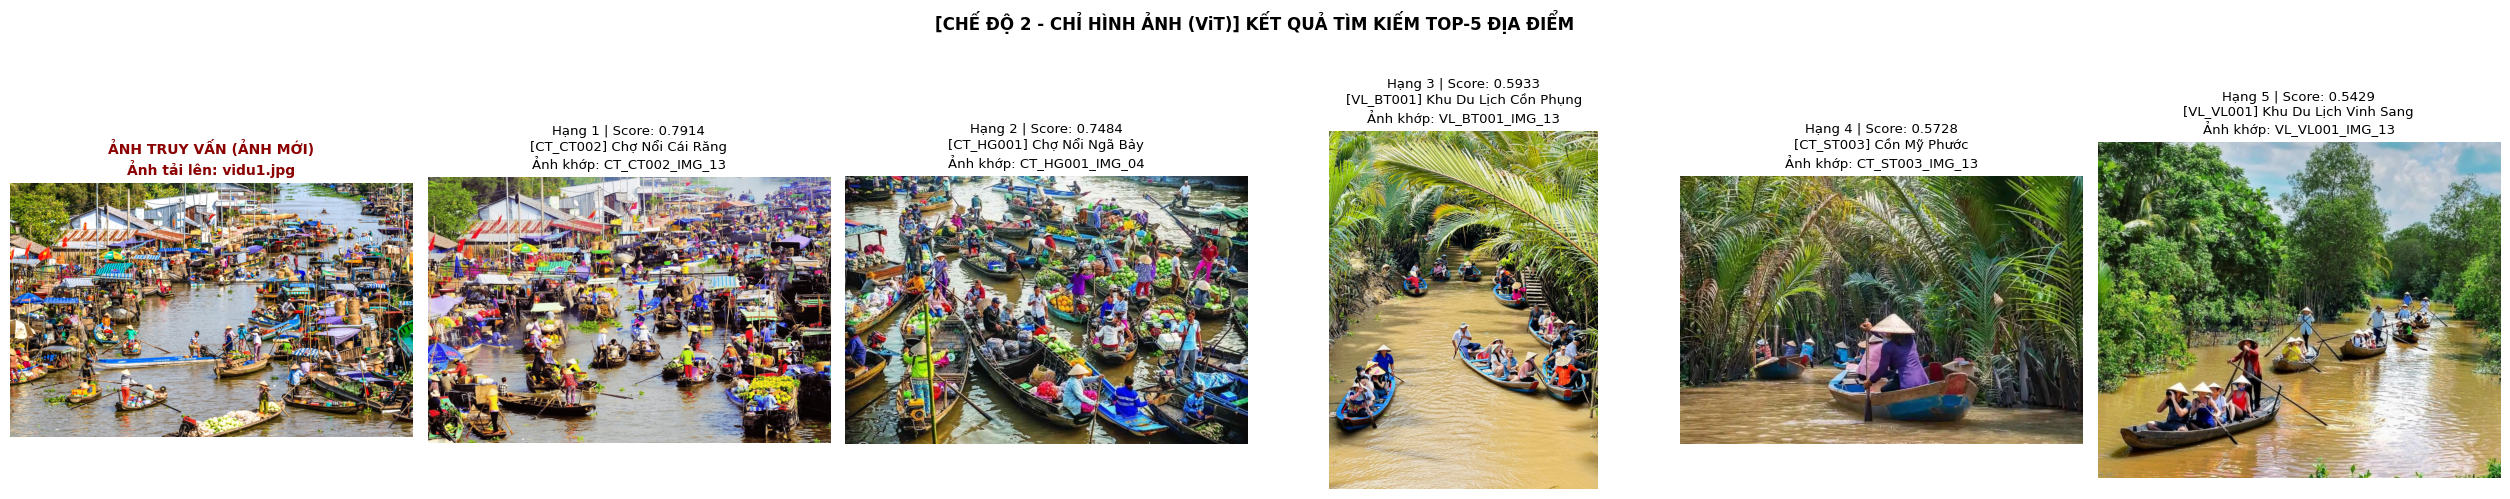

[CHẾ ĐỘ 2 - CHỈ HÌNH ẢNH (ViT)] KẾT QUẢ TÌM KIẾM TOP-5 ĐỊA ĐIỂM
Hạng 1: [CT_CT002] Chợ Nổi Cái Răng (Score: 0.7914)
   -> Ảnh khớp nhất trong kho : CT_CT002_IMG_13 (images/01_Can_Tho/02_Cho_Noi_Cai_Rang/cho_noi_cai_rang_13.png)
   -> Chú thích của ảnh khớp  : Cảnh buôn bán tấp nập với nhiều ghe thuyền và xuồng nhỏ chở đầy rau củ, trái cây neo đậu xen kẽ nhau trên sông. Người bán đội nón lá che dù bạt, phía bờ là dãy nhà lợp mái tôn san sát.
Hạng 2: [CT_HG001] Chợ Nổi Ngã Bảy (Score: 0.7484)
   -> Ảnh khớp nhất trong kho : CT_HG001_IMG_04 (images/07_Hau_Giang/01_Cho_Noi_Nga_Bay/cho_noi_nga_bay_04.jpg)
   -> Chú thích của ảnh khớp  : Góc nhìn từ trên cao xuống nhiều ghe xuồng gỗ tụ sát nhau trên sông, chở rau củ và trái cây, trong đó thấy rõ bắp cải và dưa hấu. Người bán ngồi hoặc đứng giữa hàng hóa, có người cầm mái chèo len giữa các ghe.
Hạng 3: [VL_BT001] Khu Du Lịch Cồn Phụng (Score: 0.5933)
   -> Ảnh khớp nhất trong kho : VL_BT001_IMG_13 (images/03_Ben_Tre/01_Khu_Du_Lich_Con_Phung/k

In [14]:
# ==============================================================================
# DEMO 2: TÌM KIẾM TRÊN ẢNH MỚI (CHẾ ĐỘ 2 - CHỈ HÌNH ẢNH VỚI VIT TRÊN KHO 2)
# ==============================================================================
import io
import textwrap
import urllib.request
import matplotlib.pyplot as plt

def load_external_query_image(image_source: str = ""):
    """
    Tải ảnh truy vấn mới (ngoài kho dữ liệu) từ 1 trong 3 nguồn:
    - Để trống "": Bấm chọn file ảnh tải trực tiếp từ máy tính lên Google Colab.
    - Link URL (http:// hoặc https://): Tự động tải ảnh từ liên kết web.
    - Đường dẫn file trên Google Drive / Colab: Đọc trực tiếp từ ổ đĩa.
    """
    source_str = (image_source or "").strip()
    if not source_str:
        from google.colab import files
        print("Vui lòng chọn 1 file ảnh từ máy tính để tải lên Colab...")
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("Bạn chưa chọn file ảnh nào để tải lên!")
        file_name = next(iter(uploaded.keys()))
        img_bytes = uploaded[file_name]
        pil_img = Image.open(io.BytesIO(img_bytes)).convert("RGB")
        return pil_img, f"Ảnh tải lên: {file_name}"

    if source_str.startswith(("http://", "https://")):
        req = urllib.request.Request(source_str, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=15) as resp:
            img_bytes = resp.read()
        pil_img = Image.open(io.BytesIO(img_bytes)).convert("RGB")
        return pil_img, f"Link ảnh: {source_str}"

    if os.path.exists(source_str):
        with Image.open(source_str) as img:
            pil_img = img.convert("RGB")
        return pil_img, f"File đường dẫn: {os.path.basename(source_str)}"

    raise FileNotFoundError(f"Không tìm thấy nguồn ảnh: {source_str}")

def display_visual_search_results(query_pil_img: Image.Image, query_label: str, results: list, header: str):
    """Hiển thị trực quan Ảnh truy vấn (bên trái) cùng các Ảnh kết quả Top-K (bên phải) và in chi tiết bằng chứng."""
    num_cols = 1 + len(results)
    fig, axes = plt.subplots(1, num_cols, figsize=(4.2 * num_cols, 4.8))
    if num_cols == 1:
        axes = [axes]

    # Cột 0: Hiển thị ảnh truy vấn mới của người dùng
    axes[0].imshow(query_pil_img)
    axes[0].set_title(
        "ẢNH TRUY VẤN (ẢNH MỚI)\n" + textwrap.fill(query_label, width=28),
        fontsize=10,
        fontweight="bold",
        color="darkred",
    )
    axes[0].axis("off")

    # Các cột 1..K: Hiển thị ảnh bằng chứng khớp nhất của Top-K địa điểm trong Kho 2
    for idx, item in enumerate(results, start=1):
        ev = item["best_evidence"]
        matched_img_path = os.path.join(RAW_DATA_DIR, ev["image_path"])
        with Image.open(matched_img_path) as m_img:
            axes[idx].imshow(m_img.convert("RGB"))
        title_text = (
            f"Hạng {item['rank']} | Score: {item['score']:.4f}\n"
            f"[{item['place_id']}] {item['place_name']}\n"
            f"Ảnh khớp: {ev['image_id']}"
        )
        axes[idx].set_title(title_text, fontsize=9.5)
        axes[idx].axis("off")

    plt.suptitle(header, fontsize=12, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

    # In thông tin chi tiết của từng địa điểm và cặp ảnh - chú thích khớp nhất
    print("=" * 100)
    print(header)
    print("=" * 100)
    for item in results:
        ev = item["best_evidence"]
        print(f"Hạng {item['rank']}: [{item['place_id']}] {item['place_name']} (Score: {item['score']:.4f})")
        print(f"   -> Ảnh khớp nhất trong kho : {ev['image_id']} ({ev['image_path']})")
        print(f"   -> Chú thích của ảnh khớp  : {ev['caption_snippet']}")
    print("\n")

# HƯỚNG DẪN:
# - Điền link URL ảnh (http/https) hoặc đường dẫn ảnh trên Drive vào IMAGE_SOURCE_MODE2.
# - Hoặc giữ nguyên IMAGE_SOURCE_MODE2 = "" để bấm nút tải ảnh trực tiếp từ máy tính lên Colab.
IMAGE_SOURCE_MODE2 = ""
TOP_K_MODE2 = 5

query_img_mode2, query_label_mode2 = load_external_query_image(IMAGE_SOURCE_MODE2)
results_mode2 = search_image_only(query_img_mode2, top_k=TOP_K_MODE2)
display_visual_search_results(
    query_pil_img=query_img_mode2,
    query_label=query_label_mode2,
    results=results_mode2,
    header="[CHẾ ĐỘ 2 - CHỈ HÌNH ẢNH (ViT)] KẾT QUẢ TÌM KIẾM TOP-5 ĐỊA ĐIỂM",
)

Vui lòng chọn 1 file ảnh từ máy tính để tải lên Colab...


Saving vidu1.jpg to vidu1 (1).jpg


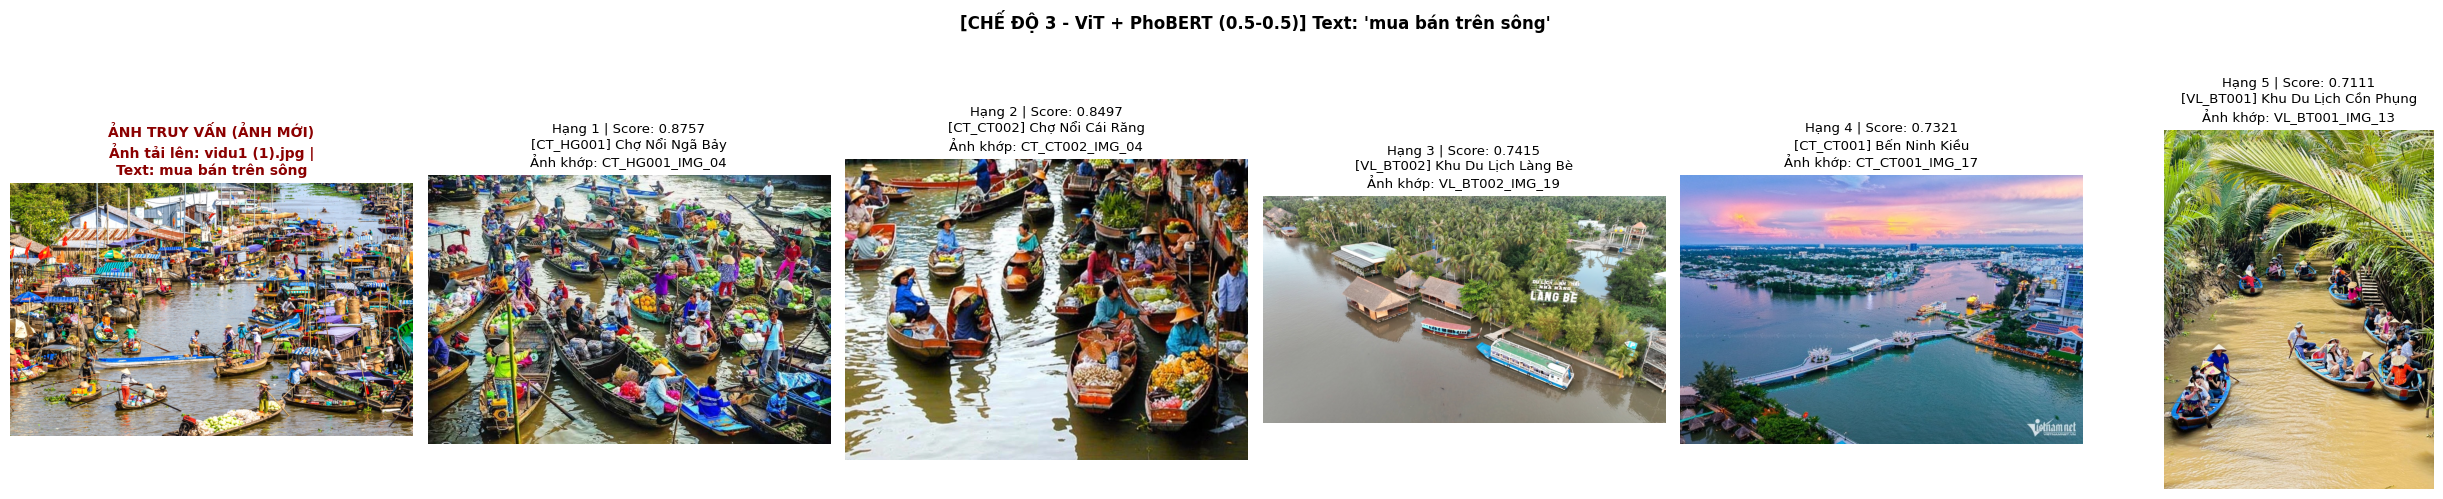

[CHẾ ĐỘ 3 - ViT + PhoBERT (0.5-0.5)] Text: 'mua bán trên sông'
Hạng 1: [CT_HG001] Chợ Nổi Ngã Bảy (Score: 0.8757)
   -> Ảnh khớp nhất trong kho : CT_HG001_IMG_04 (images/07_Hau_Giang/01_Cho_Noi_Nga_Bay/cho_noi_nga_bay_04.jpg)
   -> Chú thích của ảnh khớp  : Góc nhìn từ trên cao xuống nhiều ghe xuồng gỗ tụ sát nhau trên sông, chở rau củ và trái cây, trong đó thấy rõ bắp cải và dưa hấu. Người bán ngồi hoặc đứng giữa hàng hóa, có người cầm mái chèo len giữa các ghe.
Hạng 2: [CT_CT002] Chợ Nổi Cái Răng (Score: 0.8497)
   -> Ảnh khớp nhất trong kho : CT_CT002_IMG_04 (images/01_Can_Tho/02_Cho_Noi_Cai_Rang/cho_noi_cai_rang_04.webp)
   -> Chú thích của ảnh khớp  : Nhiều xuồng gỗ chở đầy các loại trái cây, hoa quả và nông sản tập trung san sát nhau trên mặt nước sông. Người bán đội nón lá đang chèo xuồng, mua bán và trao đổi hàng hóa trên sông.
Hạng 3: [VL_BT002] Khu Du Lịch Làng Bè (Score: 0.7415)
   -> Ảnh khớp nhất trong kho : VL_BT002_IMG_19 (images/03_Ben_Tre/02_Khu_Du_Lich_Lang_Be/lang_be

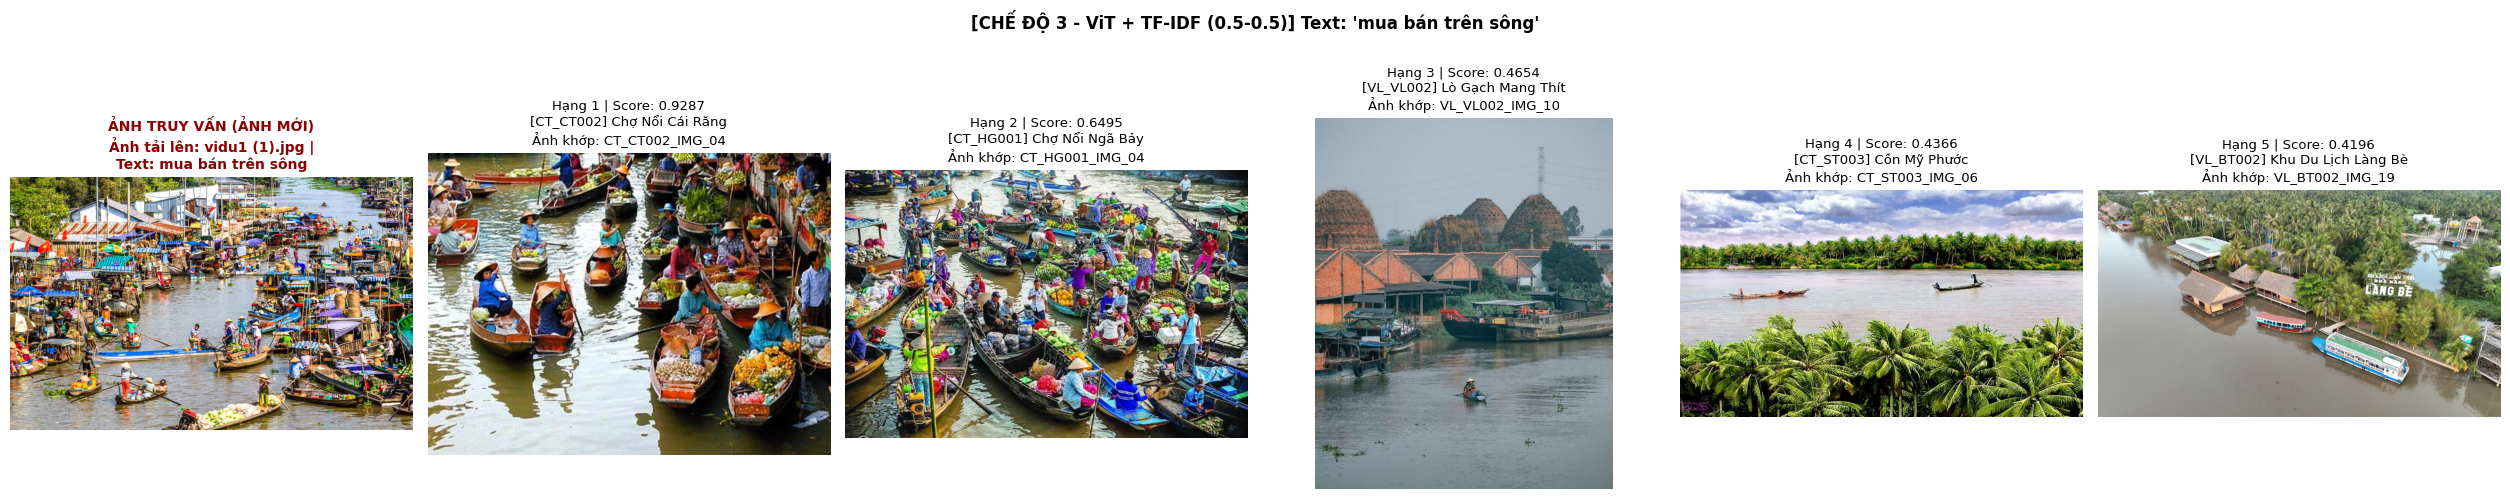

[CHẾ ĐỘ 3 - ViT + TF-IDF (0.5-0.5)] Text: 'mua bán trên sông'
Hạng 1: [CT_CT002] Chợ Nổi Cái Răng (Score: 0.9287)
   -> Ảnh khớp nhất trong kho : CT_CT002_IMG_04 (images/01_Can_Tho/02_Cho_Noi_Cai_Rang/cho_noi_cai_rang_04.webp)
   -> Chú thích của ảnh khớp  : Nhiều xuồng gỗ chở đầy các loại trái cây, hoa quả và nông sản tập trung san sát nhau trên mặt nước sông. Người bán đội nón lá đang chèo xuồng, mua bán và trao đổi hàng hóa trên sông.
Hạng 2: [CT_HG001] Chợ Nổi Ngã Bảy (Score: 0.6495)
   -> Ảnh khớp nhất trong kho : CT_HG001_IMG_04 (images/07_Hau_Giang/01_Cho_Noi_Nga_Bay/cho_noi_nga_bay_04.jpg)
   -> Chú thích của ảnh khớp  : Góc nhìn từ trên cao xuống nhiều ghe xuồng gỗ tụ sát nhau trên sông, chở rau củ và trái cây, trong đó thấy rõ bắp cải và dưa hấu. Người bán ngồi hoặc đứng giữa hàng hóa, có người cầm mái chèo len giữa các ghe.
Hạng 3: [VL_VL002] Lò Gạch Mang Thít (Score: 0.4654)
   -> Ảnh khớp nhất trong kho : VL_VL002_IMG_10 (images/04_Vinh_Long/02_Lo_Gach_Mang_Thit/mang_thit_

In [16]:
# ==============================================================================
# DEMO 3: TÌM KIẾM TRÊN CẢ TEXT VÀ ẢNH MỚI (CHẾ ĐỘ 3 - LATE FUSION 0.5-0.5)
# ==============================================================================
# HƯỚNG DẪN:
# - Đặt REUSE_MODE2_IMAGE = True nếu muốn dùng lại ngay bức ảnh vừa tải ở Demo 2.
# - Hoặc đặt REUSE_MODE2_IMAGE = False và điền link ảnh / để trống IMAGE_SOURCE_MODE3 = "" để tải ảnh mới.
REUSE_MODE2_IMAGE = False
IMAGE_SOURCE_MODE3 = ""
QUERY_TEXT_MODE3 = "mua bán trên sông"
TOP_K_MODE3 = 5

if REUSE_MODE2_IMAGE and "query_img_mode2" in globals():
    query_img_mode3 = query_img_mode2
    query_label_mode3 = query_label_mode2
else:
    query_img_mode3, query_label_mode3 = load_external_query_image(IMAGE_SOURCE_MODE3)

# 1. Đa phương thức: ViT + PhoBERT (Pair-level Late Fusion 0.5 - 0.5 có chuẩn hóa Min-Max)
results_mode3_phobert = search_multimodal_late_fusion(
    query_image=query_img_mode3,
    query_text=QUERY_TEXT_MODE3,
    top_k=TOP_K_MODE3,
    text_model="phobert",
)
display_visual_search_results(
    query_pil_img=query_img_mode3,
    query_label=f"{query_label_mode3} | Text: {QUERY_TEXT_MODE3}",
    results=results_mode3_phobert,
    header=f"[CHẾ ĐỘ 3 - ViT + PhoBERT (0.5-0.5)] Text: '{QUERY_TEXT_MODE3}'",
)

# 2. Đa phương thức đối chứng: ViT + TF-IDF (Pair-level Late Fusion 0.5 - 0.5 có chuẩn hóa Min-Max)
results_mode3_tfidf = search_multimodal_late_fusion(
    query_image=query_img_mode3,
    query_text=QUERY_TEXT_MODE3,
    top_k=TOP_K_MODE3,
    text_model="tfidf",
)
display_visual_search_results(
    query_pil_img=query_img_mode3,
    query_label=f"{query_label_mode3} | Text: {QUERY_TEXT_MODE3}",
    results=results_mode3_tfidf,
    header=f"[CHẾ ĐỘ 3 - ViT + TF-IDF (0.5-0.5)] Text: '{QUERY_TEXT_MODE3}'",
)

### Bước 4.4: Xuất 3 file `.index` của FAISS + 2 file `mapping.json` giàu metadata & `tfidf_baseline.pkl`

In [17]:
import joblib

desc_index_path = os.path.join(FAISS_STORE_DIR, "desc_phobert.index")
img_index_path = os.path.join(FAISS_STORE_DIR, "img_vit.index")
cap_index_path = os.path.join(FAISS_STORE_DIR, "cap_phobert.index")
desc_map_path = os.path.join(FAISS_STORE_DIR, "desc_mapping.json")
pair_map_path = os.path.join(FAISS_STORE_DIR, "pair_mapping.json")
tfidf_pkl_path = os.path.join(EXPERIMENTS_DIR, "tfidf_baseline.pkl")

# 1. Ghi 3 file chỉ mục FAISS (.index)
faiss.write_index(index_desc_phobert, desc_index_path)
faiss.write_index(index_img_vit, img_index_path)
faiss.write_index(index_cap_phobert, cap_index_path)

# 2. Ghi 2 file ánh xạ giàu metadata (.json)
with open(desc_map_path, "w", encoding="utf-8") as f:
    json.dump(desc_mapping, f, ensure_ascii=False, indent=2)

with open(pair_map_path, "w", encoding="utf-8") as f:
    json.dump(pair_mapping, f, ensure_ascii=False, indent=2)

# 3. Đóng gói riêng bộ TF-IDF Baseline vào thư mục experiments/
joblib.dump(
    {
        "tfidf_desc_vectorizer": tfidf_desc_vectorizer,
        "desc_tfidf_vecs": desc_tfidf_vecs,
        "tfidf_cap_vectorizer": tfidf_cap_vectorizer,
        "cap_tfidf_vecs": cap_tfidf_vecs,
    },
    tfidf_pkl_path,
)

# 4. Đọc ngược lại từ ổ cứng để kiểm chứng toàn vẹn
check_desc_idx = faiss.read_index(desc_index_path)
check_img_idx = faiss.read_index(img_index_path)
check_cap_idx = faiss.read_index(cap_index_path)

assert check_desc_idx.ntotal == 268 and check_desc_idx.d == 768
assert check_img_idx.ntotal == 866 and check_img_idx.d == 768
assert check_cap_idx.ntotal == 866 and check_cap_idx.d == 768

print("Đã xuất thành công toàn bộ file đầu ra của Mốc 1 -> Mốc 4:")
for file_path in [desc_index_path, img_index_path, cap_index_path, desc_map_path, pair_map_path, tfidf_pkl_path]:
    size_kb = os.path.getsize(file_path) / 1024.0
    print(f"  - {os.path.basename(file_path):22s}: {size_kb:8.1f} KB ({file_path})")
print("[HOÀN TẤT MỐC 4] Toàn bộ tài nguyên trong 'outputs/faiss_store/' đã sẵn sàng.")

Đã xuất thành công toàn bộ file đầu ra của Mốc 1 -> Mốc 4:
  - desc_phobert.index    :    804.0 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store/desc_phobert.index)
  - img_vit.index         :   2598.0 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store/img_vit.index)
  - cap_phobert.index     :   2598.0 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store/cap_phobert.index)
  - desc_mapping.json     :    122.9 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store/desc_mapping.json)
  - pair_mapping.json     :    388.7 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/faiss_store/pair_mapping.json)
  - tfidf_baseline.pkl    :   1432.9 KB (/content/drive/MyDrive/NAM_HOC_26_27/HKI/CT208E_NLN/notebooks/outputs/experiments/tfidf_baseline.pkl)
[HOÀN TẤT MỐC 4] Toàn bộ tài nguyên trong 'outputs/faiss_store/' đã sẵn sàng.
